# Cleaning data

- download the datasets and mount on drive for faster access and persistence

In [4]:
from google.colab import drive
import kagglehub
import os

drive.mount('/content/drive')

# downloading the data sets (the first 2 are for training & validation ; the last one is for cross-validation)
path_fares = kagglehub.dataset_download("faresabbasai2022/skin-burns-dataset")
print("fares: ", path_fares)

path_shubham = kagglehub.dataset_download("shubhambaid/skin-burn-dataset")
print("shubham: ", path_shubham)

path_sayeem = kagglehub.dataset_download("sayeemzzzaman/burn-dataset-cleanedv2-augmented")
print("sayeem:", path_sayeem)

print("Datasets downloaded successfully")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using Colab cache for faster access to the 'skin-burns-dataset' dataset.
fares:  /kaggle/input/skin-burns-dataset
Using Colab cache for faster access to the 'skin-burn-dataset' dataset.
shubham:  /kaggle/input/skin-burn-dataset
sayeem: /root/.cache/kagglehub/datasets/sayeemzzzaman/burn-dataset-cleanedv2-augmented/versions/1
Datasets downloaded successfully


- split data in directories & convert images to a certain format and save them in drive

In [5]:
import shutil
import hashlib
from PIL import Image

drive_train_dir             = '/content/Burn_Project/train_val_clean'
drive_cross_validation_dir  = '/content/Burn_Project/crossval_clean'

# clear out partial runs -> counts stay clean
if os.path.exists('/content/Burn_Project'):
    shutil.rmtree('/content/Burn_Project')

# create subdirectories for burn degrees (1st, 2nd, 3rd)
for base_dir in [drive_train_dir, drive_cross_validation_dir]:
    for degree in ['degree_1', 'degree_2', 'degree_3']:
        os.makedirs(os.path.join(base_dir, degree), exist_ok=True)

print("Local subdirectories created")

# reset duplicate tracker
seen_image_hashes = set()

def process_and_save_image(input_path, target_folder, prefix="img"):
    try:
        img = Image.open(input_path)

        if img.mode != 'RGB':
            img = img.convert('RGB')

        img_resized = img.resize((224, 224))

        # MD5 hash of pixel bytes -> avoid duplicates
        img_bytes = img_resized.tobytes()
        img_hash  = hashlib.md5(img_bytes).hexdigest()

        if img_hash in seen_image_hashes:
            return False

        seen_image_hashes.add(img_hash)

        filename  = f"{prefix}_{img_hash[:10]}.jpg"
        save_path = os.path.join(target_folder, filename)
        img_resized.save(save_path, format='JPEG', quality=95)

        return True

    except Exception as e:
        print(f"Skipping corrupt file {input_path}: {e}")
        return False

Local subdirectories created


- create final folders with cleaned images

In [6]:
import os
import hashlib
from PIL import Image
from concurrent.futures import ThreadPoolExecutor

# force 3x224x224, deduplicates, and saves
def save_pil_image(img, target_folder, prefix="img"):
    if img.mode != 'RGB':
        img = img.convert('RGB')

    img_resized = img.resize((224, 224))

    # generate an MD5 fingerprint to catch duplicate images
    img_hash = hashlib.md5(img_resized.tobytes()).hexdigest()

    if img_hash in seen_image_hashes:
        return False
    seen_image_hashes.add(img_hash)

    # save to target local folder as a high-quality JPEG
    save_path = os.path.join(target_folder, f"{prefix}_{img_hash[:10]}.jpg")
    img_resized.save(save_path, format='JPEG', quality=95)
    return True


# process a single image file (multiple threads work on multiple images)
def process_file_task(task):
    input_path, target_folder, prefix = task
    try:
        # open image safely
        with Image.open(input_path) as img:
            return save_pil_image(img, target_folder, prefix)
    except Exception:
        # skip any corrupted or unreadable images
        return False


# standardize subfolder names into 'degree_1', 'degree_2', or 'degree_3'
def get_degree_from_folder(folder_path):
    folder_name = os.path.basename(folder_path).lower()
    parent_dir = os.path.dirname(folder_path)

    # inspect sibling folders to know if the dataset uses 0-indexed (0,1,2) or 1-indexed (1,2,3) numbering
    sibling_names = [d.lower() for d in os.listdir(parent_dir)] if os.path.exists(parent_dir) else []

    # match explicit text names first
    if any(k in folder_name for k in ['1st', 'first', 'degree_1']):
        return 'degree_1'
    if any(k in folder_name for k in ['2nd', 'second', 'degree_2']):
        return 'degree_2'
    if any(k in folder_name for k in ['3rd', 'third', 'degree_3']):
        return 'degree_3'

    # handle 0-indexed folders (0 -> degree_1, 1 -> degree_2, 2 -> degree_3)
    if '0' in sibling_names:
        return {'0': 'degree_1', '1': 'degree_2', '2': 'degree_3'}.get(folder_name)

    # handle 1-indexed folders
    return {'1': 'degree_1', '2': 'degree_2', '3': 'degree_3'}.get(folder_name)


# scan a dataset directory and build a list of (source_path, destination_folder, prefix) jobs
def collect_folder_tasks(dataset_root, dest_base_dir, prefix):
    tasks = []
    for root, _, files in os.walk(dataset_root):
        degree = get_degree_from_folder(root)
        if degree is None:
            continue  # ignore parent/root folders that don't represent a burn degree
        target = os.path.join(dest_base_dir, degree)
        for file in files:
            if file.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp')):
                tasks.append((os.path.join(root, file), target, prefix))
    return tasks


# fares & sayeem
# gather all file paths -> distribute them across 16 parallel worker threads
fares_tasks  = collect_folder_tasks(path_fares,  drive_train_dir,            "fares")
sayeem_tasks = collect_folder_tasks(path_sayeem, drive_cross_validation_dir, "sayeem_cv")

print(f"Processing {len(fares_tasks)} Fares images and {len(sayeem_tasks)} Sayeem images...")

# process 16 images simultaneously
with ThreadPoolExecutor(max_workers=16) as executor:
    fares_saved  = sum(executor.map(process_file_task, fares_tasks))
    sayeem_saved = sum(executor.map(process_file_task, sayeem_tasks))

print(f"Fares: {fares_saved} | Sayeem cross-validation: {sayeem_saved}")


# shubham
YOLO_CLASS_MAP = {'0': 'degree_1', '1': 'degree_2', '2': 'degree_3'}
shubham_full_saved, shubham_crop_saved = 0, 0

# build a quick lookup dictionary mapping base filenames to their full image path
shubham_images = {
    os.path.splitext(f)[0]: os.path.join(root, f)
    for root, _, files in os.walk(path_shubham)
    for f in files if f.lower().endswith(('.jpg', '.jpeg', '.png'))
}

# loop through every YOLO annotation (.txt) file
for root, _, files in os.walk(path_shubham):
    for file in files:
        # skip non-label files and the metadata 'classes.txt' file
        if not file.lower().endswith('.txt') or file.lower() == 'classes.txt':
            continue

        base_name = os.path.splitext(file)[0]
        if base_name not in shubham_images:
            continue  # skip orphan .txt files that don't have a matching image

        # read all bounding box lines inside the label file
        with open(os.path.join(root, file), 'r') as f:
            lines = [line.strip().split() for line in f if line.strip()]
        if not lines:
            continue

        try:
            with Image.open(shubham_images[base_name]) as img:
                w_img, h_img = img.size
                found_degrees = []

                # crop out each burn bounding box in memory -> save it
                for idx, parts in enumerate(lines):
                    if len(parts) >= 5 and parts[0] in YOLO_CLASS_MAP:
                        deg = YOLO_CLASS_MAP[parts[0]]
                        found_degrees.append(deg)

                        # convert normalized YOLO coordinates (0.0, 1.0) into pixel boundaries
                        xc, yc, wb, hb = map(float, parts[1:5])
                        left, top     = max(0, int((xc - wb / 2) * w_img)), max(0, int((yc - hb / 2) * h_img))
                        right, bottom = min(w_img, int((xc + wb / 2) * w_img)), min(h_img, int((yc + hb / 2) * h_img))

                        # only keep valid / big enough crops
                        if right - left >= 10 and bottom - top >= 10:
                            cropped_burn = img.crop((left, top, right, bottom))
                            if save_pil_image(cropped_burn, os.path.join(drive_train_dir, deg), f"shubham_crop{idx}"):
                                shubham_crop_saved += 1

                # save the full, uncropped photo labeled by its most severe burn degree
                if found_degrees:
                    highest_severity = max(found_degrees)  # 'degree_3' > 'degree_2' > 'degree_1'
                    if save_pil_image(img, os.path.join(drive_train_dir, highest_severity), "shubham_full"):
                        shubham_full_saved += 1
        except Exception:
            continue

print(f"Shubham complete ; full: {shubham_full_saved} | cropped: {shubham_crop_saved}")


# verify final count
print("\nImage counts saved:")
for label, base_path in [("training/validation set", drive_train_dir), ("cross-validation set", drive_cross_validation_dir)]:
    print(f"\n{label}:")
    for deg in ['degree_1', 'degree_2', 'degree_3']:
        print(f"  {deg}: {len(os.listdir(os.path.join(base_path, deg)))} images")

Processing 34937 Fares images and 4127 Sayeem images...
Fares: 33080 | Sayeem cross-validation: 3319
Shubham complete ; full: 125 | cropped: 2206

Image counts saved:

training/validation set:
  degree_1: 18077 images
  degree_2: 16854 images
  degree_3: 480 images

cross-validation set:
  degree_1: 1194 images
  degree_2: 1125 images
  degree_3: 1000 images


- save data to drive

In [7]:
# create permanent project directory inside Drive if it doesn't exist yet
!mkdir -p /content/drive/MyDrive/Burn_Project

# all cleaned local folders -> one .zip on Drive
!zip -r -q /content/drive/MyDrive/Burn_Project/cleaned_burn_data.zip /content/Burn_Project

print("Saved data permanently to Drive")

Saved data permanently to Drive


# Model logic

- ensure reproductibility

In [8]:
import random
import os
import torch
import numpy as np
from google.colab import drive
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset, WeightedRandomSampler
from sklearn.model_selection import train_test_split

def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    # Forces cuDNN to use deterministic algorithms (slightly slower, but 100% repeatable)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = True

seed_everything(42)

In [9]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# mount Drive -> unzip cleaned dataset to local SSD (if not already unzipped)
drive.mount('/content/drive')
if not os.path.exists('/content/Burn_Project'):
    !unzip -q /content/drive/MyDrive/Burn_Project/cleaned_burn_data.zip -d /
    print("Unzipped cleaned dataset from Google Drive!")

train_validation_path  = '/content/Burn_Project/train_val_clean'
cross_validation_path  = '/content/Burn_Project/crossval_clean'

# ImageNet normalization required by pretrained MobileNetV3-Large
imagenet_norm = transforms.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225]
)

# heavy augmentation helps prevent overfitting on oversampled 3rd degree burns
train_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomResizedCrop(size=224, scale=(0.55, 1.0)),
    transforms.RandomRotation(degrees=180),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.1, hue=0.02),
    transforms.ToTensor(),
    imagenet_norm
])

# no augmentations for validation & cross-validation
eval_transforms = transforms.Compose([
    transforms.ToTensor(),
    imagenet_norm
])

# load datasets
full_train_dataset         = datasets.ImageFolder(root=train_validation_path, transform=train_transforms)
full_val_dataset           = datasets.ImageFolder(root=train_validation_path, transform=eval_transforms)
cross_validation_dataset   = datasets.ImageFolder(root=cross_validation_path,  transform=eval_transforms)

print("Class mapping:", full_train_dataset.class_to_idx)  # {'degree_1': 0, 'degree_2': 1, 'degree_3': 2}

# 80/20 split
all_indices = np.arange(len(full_train_dataset))
all_targets = np.array(full_train_dataset.targets)

train_indices, val_indices = train_test_split(
    all_indices,
    test_size=0.20,
    stratify=all_targets,
    random_state=42
)

train_subset = Subset(full_train_dataset, train_indices)
val_subset   = Subset(full_val_dataset, val_indices)

# build a WeightedRandomSampler so every training epoch sees equal numbers of degree_1, degree_2, degree_3 (it alraedy shuffles the data)
train_targets = all_targets[train_indices]
class_counts = np.bincount(train_targets)
print("Training split counts per class (1st, 2nd, 3rd degree):", class_counts)

class_weights = 1.0 / class_counts
sample_weights = class_weights[train_targets]

# sampling 4,500 balanced images per epoch (~1,500 of each degree) for fast, unbiased learning
g = torch.Generator().manual_seed(42)
balanced_sampler = WeightedRandomSampler(
    weights=torch.DoubleTensor(sample_weights),
    num_samples=6000,
    replacement=True,
    generator=g
)

# create DataLoaders (Note: shuffle=False is required when using a sampler)
BATCH_SIZE = 64
use_cuda = (device.type == "cuda")

train_loader = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    sampler=balanced_sampler,
    num_workers=2,
    pin_memory=use_cuda,
    persistent_workers=True,
    drop_last=True           # prevents a 1-sample final batch from crashing BatchNorm1d
)

val_loader = DataLoader(
    val_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=use_cuda,
    persistent_workers=True # speeds-up validation between epochs
)

cross_validation_loader = DataLoader(cross_validation_dataset, batch_size=BATCH_SIZE, shuffle=False,            num_workers=2, pin_memory=True)

print(f"training samples per epoch: {len(balanced_sampler)} (balanced across all 3 degrees)")
print(f"validation images:          {len(val_subset)}")
print(f"cross-validation images:    {len(cross_validation_dataset)}")

Using device: cuda
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Class mapping: {'degree_1': 0, 'degree_2': 1, 'degree_3': 2}
Training split counts per class (1st, 2nd, 3rd degree): [14461 13483   384]
training samples per epoch: 6000 (balanced across all 3 degrees)
validation images:          7083
cross-validation images:    3322


- training the model

In [10]:
import copy
import time
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from sklearn.metrics import f1_score

# model arhitecture: MobileNetV3-Large + Custom Head

class BurnClassifier(nn.Module):
    def __init__(self, num_classes=3, dropout_rate=0.4):
        super().__init__()
        # load pretrained MobileNetV3-Large backbone
        weights = models.MobileNet_V3_Large_Weights.DEFAULT
        self.backbone = models.mobilenet_v3_large(weights=weights)

        # MobileNetV3-Large's final classifier expects 960 features from the pooled backbone
        in_features = self.backbone.classifier[0].in_features

        # Replace the default 1000-class ImageNet head with our custom regularized head
        self.backbone.classifier = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.BatchNorm1d(512),
            nn.Hardswish(),
            nn.Dropout(p=dropout_rate),
            nn.Linear(512, num_classes)  # outputs raw logits for CrossEntropyLoss
        )

        # Apply Xavier initialization to our custom Linear layers
        self._init_custom_weights()

    def _init_custom_weights(self):
        for m in self.backbone.classifier.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.backbone(x)

    def predict_proba(self, x):
        """returns Softmax probabilities [P(1st burn), P(2nd burn), P(3rd burn)] for JEV Decision API."""
        logits = self.forward(x)
        return torch.softmax(logits, dim=1)


model = BurnClassifier(num_classes=3, dropout_rate=0.4).to(device)

# extra penalty for 3rd degree burn for patient safety
criterion = nn.CrossEntropyLoss(weight=torch.tensor([1.15, 0.9, 1.4], device=device), # penalize dumping 1st/3rd degree into 2nd degree class
                                label_smoothing=0.05) # prevents overconfident probabilities like 0.999 for JEV API

# training and validation functions

# automatic mixed precision (FP16) scaler cuts epoch time roughly in half
use_amp = (device.type == "cuda")
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

def run_phase(model, optimizer, scheduler, num_epochs, phase_name, patience=4, best_f1=0.0, best_weights=None):
    if best_weights is None:
        best_weights = copy.deepcopy(model.state_dict())

    epochs_no_improve = 0
    best_path = '/content/drive/MyDrive/Burn_Project/best_burn_mobilenetv3.pth'

    for epoch in range(1, num_epochs + 1):
        start_time = time.time()

        # training step
        model.train()
        train_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * images.size(0)

        train_loss /= len(train_loader.sampler)

        # --- VALIDATION STEP ---
        model.eval()
        val_loss = 0.0
        all_preds, all_labels = [], []

        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                logits = model(images)
                loss = criterion(logits, labels) # extra penalty for 3rd degree burns

                val_loss += loss.item() * images.size(0)
                preds = torch.argmax(logits, dim=1)
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())

        val_loss /= len(val_loader.dataset)
        val_acc = (torch.tensor(all_preds) == torch.tensor(all_labels)).float().mean().item()
        val_macro_f1 = f1_score(all_labels, all_preds, average='macro')

        if scheduler is not None:
            scheduler.step(val_macro_f1)

        elapsed = time.time() - start_time
        print(f"[{phase_name}] Epoch {epoch}/{num_epochs} ({elapsed:.1f}s) | "
              f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | "
              f"Val Acc: {val_acc*100:.2f}% | Val Macro-F1: {val_macro_f1:.4f}")

        # save checkpoint if Macro-F1 improves (unweighted average of the F1 score that has 2 safet measyres: recall, aka how many dkid the models catch)
        # and precision (how often the model is right)
        if val_macro_f1 > best_f1:
            best_f1 = val_macro_f1
            best_weights = copy.deepcopy(model.state_dict())
            torch.save(best_weights, best_path)
            epochs_no_improve = 0
            print(f"New best model saved (Macro-F1: {best_f1:.4f})")
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping triggered after {epoch} epochs")
                break

    model.load_state_dict(best_weights)
    return model, best_f1, best_weights

# phase 1: warm up custom head (backbone is frozen)
print("PHASE 1: Training custom classifier head (backbone is frozen)")
for param in model.backbone.features.parameters():
    param.requires_grad = False

optimizer_p1 = optim.AdamW(model.backbone.classifier.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler_p1 = optim.lr_scheduler.ReduceLROnPlateau(optimizer_p1, mode='max', factor=0.5, patience=2)

model, best_f1, best_weights = run_phase(
    model, optimizer_p1, scheduler_p1, num_epochs=100, phase_name="Phase 1", patience=3
)

# phase 2: fine-tune the entire network (backbone unfrozen)
print("\n--- PHASE 2: Fine-Tuning Full MobileNetV3-Large Network ---")
for param in model.backbone.features.parameters():
    param.requires_grad = True

# Use a lower learning rate for the pretrained backbone and slightly higher for the head
optimizer_p2 = optim.AdamW([
    {'params': model.backbone.features.parameters(), 'lr': 1e-4},
    {'params': model.backbone.classifier.parameters(), 'lr': 5e-4}
], weight_decay=1e-4)
scheduler_p2 = optim.lr_scheduler.ReduceLROnPlateau(optimizer_p2, mode='max', factor=0.5, patience=2)

model, best_f1, best_weights = run_phase(
    model, optimizer_p2, scheduler_p2, num_epochs=100, phase_name="Phase 2", patience=4,
    best_f1=best_f1, best_weights=best_weights
)

print(f"\nTraining complete! Best Validation Macro-F1: {best_f1:.4f}")

PHASE 1: Training custom classifier head (backbone is frozen)
[Phase 1] Epoch 1/100 (65.0s) | Train Loss: 0.7173 | Val Loss: 0.6554 | Val Acc: 73.20% | Val Macro-F1: 0.6009
New best model saved (Macro-F1: 0.6009)
[Phase 1] Epoch 2/100 (62.4s) | Train Loss: 0.5932 | Val Loss: 0.6281 | Val Acc: 76.32% | Val Macro-F1: 0.6130
New best model saved (Macro-F1: 0.6130)
[Phase 1] Epoch 3/100 (62.4s) | Train Loss: 0.5564 | Val Loss: 0.7152 | Val Acc: 73.01% | Val Macro-F1: 0.5730
[Phase 1] Epoch 4/100 (61.8s) | Train Loss: 0.5447 | Val Loss: 0.6432 | Val Acc: 76.85% | Val Macro-F1: 0.6098
[Phase 1] Epoch 5/100 (62.1s) | Train Loss: 0.5381 | Val Loss: 0.7008 | Val Acc: 73.74% | Val Macro-F1: 0.5766
Early stopping triggered after 5 epochs

--- PHASE 2: Fine-Tuning Full MobileNetV3-Large Network ---
[Phase 2] Epoch 1/100 (66.3s) | Train Loss: 0.5275 | Val Loss: 0.5439 | Val Acc: 81.59% | Val Macro-F1: 0.6649
New best model saved (Macro-F1: 0.6649)
[Phase 2] Epoch 2/100 (68.0s) | Train Loss: 0.4745 

Cross validation report:
              precision    recall  f1-score   support

  1st Degree     0.9505    0.5628    0.7070      1194
  2nd Degree     0.5455    0.9663    0.6974      1128
  3rd Degree     0.9530    0.5880    0.7273      1000

    accuracy                         0.7074      3322
   macro avg     0.8163    0.7057    0.7105      3322
weighted avg     0.8137    0.7074    0.7098      3322

-----------------------------------------------------------------
Overall accuracy:             70.74%
Macro F1-Score:               0.7105
Cohen's Kappa:                0.5589  (>0.80 = strong clinical agreement)
Multi-Class ROC-AUC (OvR):    0.9272  (measures probability ranking quality)
Log-Loss (Calibration):       0.7378  (lower = better calibrated probabilities)
3rd-Degree Miss Rate:         41.20% (412/1000 misclassified)
Critical Miss (3rd -> 1st):   1.30% (highest patient safety risk)


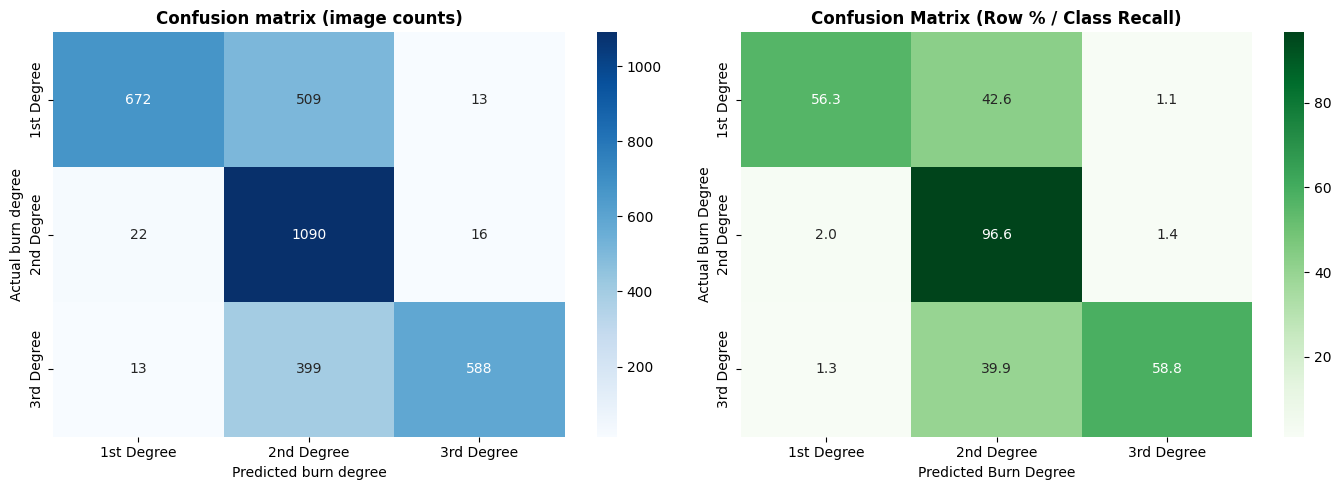

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    cohen_kappa_score,
    roc_auc_score,
    log_loss
)

best_path = '/content/drive/MyDrive/Burn_Project/best_burn_mobilenetv3.pth'
model.load_state_dict(torch.load(best_path, map_location=device))
model.eval()

eval_loader = cross_validation_loader
class_names = ['1st Degree', '2nd Degree', '3rd Degree']

# run inference across the Sayeem cross-validation dataset
all_labels = []
all_preds  = []
all_probs  = []

with torch.no_grad():
    for images, labels in eval_loader:
        images = images.to(device)

        # get calibrated Softmax probabilities [P(1st), P(2nd), P(3rd)]
        probs = model.predict_proba(images)
        preds = torch.argmax(probs, dim=1)

        all_labels.extend(labels.numpy())
        all_preds.extend(preds.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

y_true = np.array(all_labels)
y_pred = np.array(all_preds)
y_prob = np.array(all_probs)

# report and metrics
print("=" * 65)
print("Cross validation report:")
print("=" * 65)
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

overall_acc = (y_true == y_pred).mean()
macro_f1    = f1_score(y_true, y_pred, average='macro')
kappa       = cohen_kappa_score(y_true, y_pred)
roc_auc     = roc_auc_score(y_true, y_prob, multi_class='ovr', average='macro')
calib_loss  = log_loss(y_true, y_prob)

# clinical safety check: how often is a true 3rd-degree burn missed (predicted as 1st or 2nd)?
deg3_mask = (y_true == 2)
missed_deg3 = np.sum(y_pred[deg3_mask] != 2)
total_deg3  = np.sum(deg3_mask)
under_triage_rate = (missed_deg3 / total_deg3) * 100

# dangerous under-triage: true 3rd-degree burn misclassified all the way down to 1st-degree (home care)
critical_miss_rate = (np.sum(y_pred[deg3_mask] == 0) / total_deg3) * 100

print("-" * 65)
print(f"Overall accuracy:             {overall_acc * 100:.2f}%")
print(f"Macro F1-Score:               {macro_f1:.4f}")
print(f"Cohen's Kappa:                {kappa:.4f}  (>0.80 = strong clinical agreement)")
print(f"Multi-Class ROC-AUC (OvR):    {roc_auc:.4f}  (measures probability ranking quality)")
print(f"Log-Loss (Calibration):       {calib_loss:.4f}  (lower = better calibrated probabilities)")
print(f"3rd-Degree Miss Rate:         {under_triage_rate:.2f}% ({missed_deg3}/{total_deg3} misclassified)")
print(f"Critical Miss (3rd -> 1st):   {critical_miss_rate:.2f}% (highest patient safety risk)")
print("=" * 65)

# confusion matrices (percentages and counts)
cm_counts = confusion_matrix(y_true, y_pred)
cm_norm   = confusion_matrix(y_true, y_pred, normalize='true') * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# left plot: raw image counts
sns.heatmap(
    cm_counts, annot=True, fmt='d', cmap='Blues',
    xticklabels=class_names, yticklabels=class_names, ax=axes[0]
)
axes[0].set_title('Confusion matrix (image counts)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted burn degree')
axes[0].set_ylabel('Actual burn degree')

# right plot: row-normalized recall percentages
sns.heatmap(
    cm_norm, annot=True, fmt='.1f', cmap='Greens',
    xticklabels=class_names, yticklabels=class_names, ax=axes[1]
)
axes[1].set_title('Confusion Matrix (Row % / Class Recall)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Predicted Burn Degree')
axes[1].set_ylabel('Actual Burn Degree')

plt.tight_layout()
plt.show()

In [12]:
import io
from PIL import Image, ImageFilter, ImageEnhance
from sklearn.metrics import f1_score, roc_auc_score

best_path = '/content/drive/MyDrive/Burn_Project/best_burn_mobilenetv3.pth'
model.load_state_dict(torch.load(best_path, map_location=device))
model.eval()

# def img corruption
def degrade_image(img, mode):
    if mode == "clean":
        return img
    elif mode == "dim_bedroom":
        return ImageEnhance.Brightness(img).enhance(0.45)
    elif mode == "harsh_flash":
        img = ImageEnhance.Brightness(img).enhance(1.65)
        return ImageEnhance.Contrast(img).enhance(1.30)
    elif mode == "blurry_hand":
        return img.filter(ImageFilter.GaussianBlur(radius=2.2))
    elif mode == "bad_jpeg_compression":
        buf = io.BytesIO()
        img.save(buf, format="JPEG", quality=15)
        buf.seek(0)
        return Image.open(buf).convert("RGB")
    elif mode == "extreme_zoom":
        w, h = img.size
        crop = img.crop((int(w*0.2), int(h*0.2), int(w*0.8), int(h*0.8)))
        return crop.resize((224, 224))
    return img


modes = ["clean", "dim_bedroom", "harsh_flash", "blurry_hand", "bad_jpeg_compression", "extreme_zoom"]
sayeem_raw = datasets.ImageFolder(root='/content/Burn_Project/crossval_clean')

print("=" * 75)
print(f"{'Camera / Lighting Condition':<25} | {'Acc':>7} | {'Macro-F1':>8} | {'ROC-AUC':>8} | {'3rd Recall':>10}")
print("=" * 75)

for mode in modes:
    all_y, all_p, all_probs = [], [], []

    batch_imgs, batch_labels = [], []
    for path, label in sayeem_raw.samples:
        img = Image.open(path).convert("RGB")
        img = degrade_image(img, mode)
        batch_imgs.append(eval_transforms(img))
        batch_labels.append(label)

        if len(batch_imgs) == 64:
            x = torch.stack(batch_imgs).to(device)
            with torch.no_grad():
                probs = model.predict_proba(x).cpu().numpy()
            all_probs.extend(probs)
            all_p.extend(np.argmax(probs, axis=1))
            all_y.extend(batch_labels)
            batch_imgs, batch_labels = [], []

    if batch_imgs:
        x = torch.stack(batch_imgs).to(device)
        with torch.no_grad():
            probs = model.predict_proba(x).cpu().numpy()
        all_probs.extend(probs)
        all_p.extend(np.argmax(probs, axis=1))
        all_y.extend(batch_labels)

    y_true_m = np.array(all_y)
    y_pred_m = np.array(all_p)
    y_prob_m = np.array(all_probs)

    acc = (y_true_m == y_pred_m).mean() * 100
    mf1 = f1_score(y_true_m, y_pred_m, average='macro')
    auc = roc_auc_score(y_true_m, y_prob_m, multi_class='ovr', average='macro')
    deg3_rec = (y_pred_m[y_true_m == 2] == 2).mean() * 100

    print(f"{mode:<25} | {acc:>6.2f}% | {mf1:>8.4f} | {auc:>8.4f} | {deg3_rec:>9.2f}%")

print("=" * 75)

Camera / Lighting Condition |     Acc | Macro-F1 |  ROC-AUC | 3rd Recall
clean                     |  70.74% |   0.7105 |   0.9272 |     58.80%
dim_bedroom               |  68.00% |   0.6779 |   0.9045 |     49.30%
harsh_flash               |  57.98% |   0.5665 |   0.8677 |     44.40%
blurry_hand               |  66.10% |   0.6593 |   0.8740 |     85.30%
bad_jpeg_compression      |  64.57% |   0.6355 |   0.8882 |     82.80%
extreme_zoom              |  74.26% |   0.7453 |   0.9026 |     64.90%
